# Quickstart: ECMWF AIFS forecasts, virtual - dynamical.org Icechunk Zarr

ECMWF's Artificial Intelligence Forecasting System (AIFS) is an AI based global weather model. AIFS Single provides deterministic forecasts from 1 April 2024, and AIFS ENS provides 51-member forecasts from 1 July 2025 at 06 UTC; both have 0.25° resolution and run every 6 hours out to 15 days.

These virtual datasets are optimized for spatial (map) access. For point time series, use the materialized [AIFS Single](https://dynamical.org/catalog/ecmwf-aifs-single-forecast/) and [AIFS ENS](https://dynamical.org/catalog/ecmwf-aifs-ens-forecast/) datasets.

Dataset documentation:
- AIFS Single: https://dynamical.org/catalog/ecmwf-aifs-single-forecast-virtual/
- AIFS ENS: https://dynamical.org/catalog/ecmwf-aifs-ens-forecast-virtual/

Dataset licenced [CC-BY-4.0](https://creativecommons.org/licenses/by/4.0/) and [ECMWF Terms of Use](https://apps.ecmwf.int/datasets/licences/general/).

In [ ]:
# If running locally, follow README.md for simple dependency installation.
# If using Google Colab, run this cell.
!uv pip install 'dynamical-catalog>=1.0.0' cartopy

In [2]:
import dynamical_catalog
import icechunk
import xarray as xr

single = dynamical_catalog.open("ecmwf-aifs-single-forecast-virtual", chunks=None)
single_pressure = dynamical_catalog.open("ecmwf-aifs-single-forecast-virtual", group="pressure_level", chunks=None)

# TEMPORARY: open AIFS ENS directly until it is published in the dynamical.org catalog.
authorize = icechunk.containers_credentials({"gs://ecmwf-open-data/": icechunk.gcs_credentials(anonymous=True)})
storage = icechunk.s3_storage(
    bucket="dynamical-ecmwf-aifs-ens",
    prefix="ecmwf-aifs-ens-forecast-virtual/v0.1.0.icechunk",
    region="us-west-2",
    anonymous=True,
)
repo = icechunk.Repository.open(storage, authorize_virtual_chunk_access=authorize)
store = repo.readonly_session("main").store
ens = xr.open_zarr(store, chunks=None)
ens_pressure = xr.open_zarr(store, group="pressure_level", chunks=None)
ens

<xarray.Dataset> Size: 2PB
Dimensions:                                                (init_time: 2002,
                                                            lead_time: 61,
                                                            ensemble_member: 51,
                                                            latitude: 721,
                                                            longitude: 1440)
Coordinates:
  * init_time                                              (init_time) datetime64[ns] 16kB ...
    expected_forecast_length                               (init_time) timedelta64[us] 16kB ...
  * lead_time                                              (lead_time) timedelta64[us] 488B ...
    valid_time                                             (init_time, lead_time) datetime64[ns] 977kB ...
  * ensemble_member                                        (ensemble_member) int16 102B ...
  * latitude                                               (latitude) float64 6kB ...
  * longitude                                              (longitude) float64 12kB ...
    spatial_ref                                            int64 8B ...
Data variables: (12/29)
    convective_precipitation_run_total_surface             (init_time, lead_time, ensemble_member, latitude, longitude) float64 52TB ...
    dew_point_temperature_2m                               (init_time, lead_time, ensemble_member, latitude, longitude) float64 52TB ...
    downward_short_wave_radiation_run_total_surface        (init_time, lead_time, ensemble_member, latitude, longitude) float64 52TB ...
    geopotential_height_surface                            (init_time, lead_time, ensemble_member, latitude, longitude) float64 52TB ...
    downward_long_wave_radiation_run_total_surface         (init_time, lead_time, ensemble_member, latitude, longitude) float64 52TB ...
    land_sea_mask_surface                                  (init_time, lead_time, ensemble_member, latitude, longitude) float64 52TB ...
    ...                                                     ...
    wind_u_10m                                             (init_time, lead_time, ensemble_member, latitude, longitude) float64 52TB ...
    total_precipitation_run_total_surface                  (init_time, lead_time, ensemble_member, latitude, longitude) float64 52TB ...
    temperature_2m                                         (init_time, lead_time, ensemble_member, latitude, longitude) float64 52TB ...
    total_cloud_cover_atmosphere                           (init_time, lead_time, ensemble_member, latitude, longitude) float64 52TB ...
    total_column_water_atmosphere                          (init_time, lead_time, ensemble_member, latitude, longitude) float64 52TB ...
    wind_v_10m                                             (init_time, lead_time, ensemble_member, latitude, longitude) float64 52TB ...
Attributes:
    dataset_id:           ecmwf-aifs-ens-forecast-virtual
    dataset_version:      0.1.0
    name:                 ECMWF AIFS ENS forecast, virtual
    description:          Ensemble weather forecasts from the ECMWF Artificia...
    attribution:          ECMWF AIFS ENS forecast data processed by dynamical...
    license:              CC-BY-4.0
    spatial_domain:       Global
    spatial_resolution:   0.25 degrees (~20km)
    time_domain:          Forecasts initialized 2025-07-01 06:00:00 UTC to Pr...
    time_resolution:      Forecasts initialized every 6 hours
    forecast_domain:      Forecast lead time 0-360 hours (0-15 days) ahead
    forecast_resolution:  6 hourly

Member 0 is the control; AIFS Single has the same layout without `ensemble_member`. Variables on pressure levels live in the `pressure_level` group.

In [3]:
ens_pressure

<xarray.Dataset> Size: 4PB
Dimensions:                   (init_time: 2002, lead_time: 61,
                               ensemble_member: 51, latitude: 721,
                               longitude: 1440, pressure_level: 14)
Coordinates:
  * init_time                 (init_time) datetime64[ns] 16kB 2025-07-01T06:0...
    expected_forecast_length  (init_time) timedelta64[us] 16kB ...
  * lead_time                 (lead_time) timedelta64[us] 488B 0 days 00:00:0...
    valid_time                (init_time, lead_time) datetime64[ns] 977kB ...
  * ensemble_member           (ensemble_member) int16 102B 0 1 2 3 ... 48 49 50
  * latitude                  (latitude) float64 6kB 90.0 89.75 ... -89.75 -90.0
  * longitude                 (longitude) float64 12kB -180.0 -179.8 ... 179.8
  * pressure_level            (pressure_level) int64 112B 10 50 100 ... 925 1000
    spatial_ref               int64 8B ...
Data variables:
    geopotential_height       (init_time, lead_time, ensemble_member, latitude, longitude, pressure_level) float64 724TB ...
    temperature               (init_time, lead_time, ensemble_member, latitude, longitude, pressure_level) float64 724TB ...
    wind_u                    (init_time, lead_time, ensemble_member, latitude, longitude, pressure_level) float64 724TB ...
    wind_v                    (init_time, lead_time, ensemble_member, latitude, longitude, pressure_level) float64 724TB ...
    vertical_velocity         (init_time, lead_time, ensemble_member, latitude, longitude, pressure_level) float64 724TB ...
    specific_humidity         (init_time, lead_time, ensemble_member, latitude, longitude, pressure_level) float64 724TB ...
Attributes:
    dataset_id:           ecmwf-aifs-ens-forecast-virtual
    dataset_version:      0.1.0
    name:                 ECMWF AIFS ENS forecast, virtual
    description:          Ensemble weather forecasts from the ECMWF Artificia...
    attribution:          ECMWF AIFS ENS forecast data processed by dynamical...
    license:              CC-BY-4.0
    spatial_domain:       Global
    spatial_resolution:   0.25 degrees (~20km)
    time_domain:          Forecasts initialized 2025-07-01 06:00:00 UTC to Pr...
    time_resolution:      Forecasts initialized every 6 hours
    forecast_domain:      Forecast lead time 0-360 hours (0-15 days) ahead
    forecast_resolution:  6 hourly

## How much rain did AIFS forecast for the Texas Hill Country?

The [July 2025 Central Texas floods](https://www.psl.noaa.gov/news/2025/texasfloods.html) struck the Guadalupe River in Kerr County early on 4 July. These forecasts for Hunt, Texas, start at 00 UTC on 2 July: `run_total` precipitation accumulates from initialization, while differencing gives the amount in each 6-hour interval.

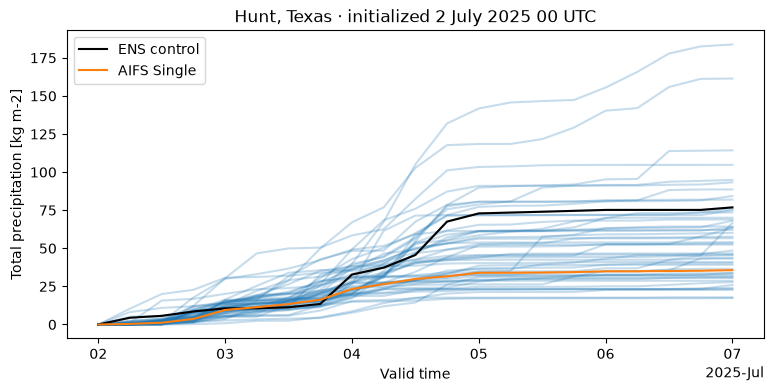

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

rain = (
    ens["total_precipitation_run_total_surface"]
    .sel(init_time="2025-07-02T00", lead_time=pd.timedelta_range("0h", "120h", freq="6h"))
    .sel(latitude=30.07, longitude=-99.34, method="nearest")
    .load()
)
single_rain = (
    single["total_precipitation_run_total_surface"]
    .sel(init_time="2025-07-02T00", lead_time=pd.timedelta_range("0h", "120h", freq="6h"))
    .sel(latitude=30.07, longitude=-99.34, method="nearest")
    .load()
)

fig, ax = plt.subplots(figsize=(9, 4))
rain.plot(x="valid_time", hue="ensemble_member", ax=ax, add_legend=False, color="tab:blue", alpha=0.25)
rain.sel(ensemble_member=0).plot(x="valid_time", ax=ax, color="black", label="ENS control")
single_rain.plot(x="valid_time", ax=ax, color="tab:orange", label="AIFS Single")
ax.set_title("Hunt, Texas · initialized 2 July 2025 00 UTC")
ax.legend();

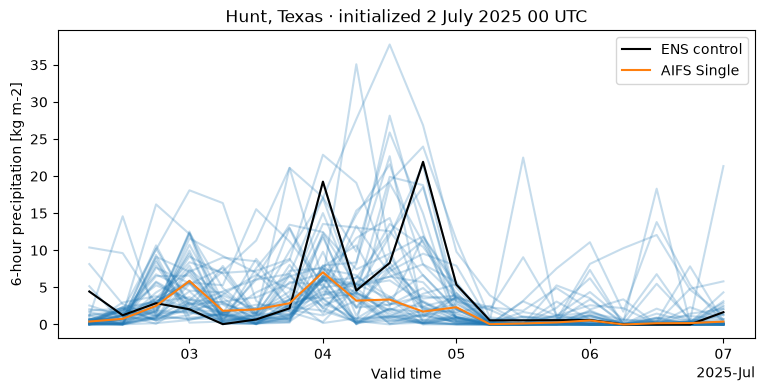

In [5]:
per_step = rain.diff("lead_time")
per_step.attrs = {"long_name": "6-hour precipitation", "units": rain.attrs["units"]}
single_per_step = single_rain.diff("lead_time")
single_per_step.attrs = per_step.attrs

fig, ax = plt.subplots(figsize=(9, 4))
per_step.plot(x="valid_time", hue="ensemble_member", ax=ax, add_legend=False, color="tab:blue", alpha=0.25)
per_step.sel(ensemble_member=0).plot(x="valid_time", ax=ax, color="black", label="ENS control")
single_per_step.plot(x="valid_time", ax=ax, color="tab:orange", label="AIFS Single")
ax.set_title("Hunt, Texas · initialized 2 July 2025 00 UTC")
ax.legend();

## How likely was heavy snow?

The [23–27 January 2026 winter storm](https://en.wikipedia.org/wiki/January_23%E2%80%9327,_2026_North_American_winter_storm) brought snow and ice from the southern United States to the Northeast. Subtracting run totals at 48 and 120 hours isolates 00 UTC on 24 January to 00 UTC on 27 January in the 22 January 00 UTC run. The map shows the fraction of members forecasting more than 25 kg m⁻² of snowfall water equivalent (25 mm of liquid water, rather than snow depth).

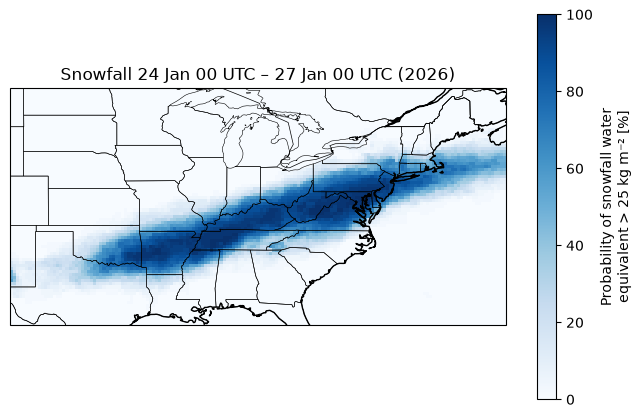

In [6]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

snow = (
    ens["snowfall_water_equivalent_run_total_surface"]
    .sel(init_time="2026-01-22T00", lead_time=pd.to_timedelta(["48h", "120h"]))
    .sel(latitude=slice(48, 29), longitude=slice(-105, -65))
    .load()
)
snow_window = snow.isel(lead_time=1) - snow.isel(lead_time=0)
probability = (snow_window > 25).mean("ensemble_member") * 100
probability.attrs = {"long_name": "Probability of snowfall water equivalent > 25 kg m⁻²", "units": "%"}

fig, ax = plt.subplots(figsize=(8, 5), subplot_kw={"projection": ccrs.PlateCarree()})
probability.plot(ax=ax, transform=ccrs.PlateCarree(), vmin=0, vmax=100, cmap="Blues")
ax.coastlines()
ax.add_feature(cfeature.BORDERS, linewidth=0.5)
ax.add_feature(cfeature.STATES, linewidth=0.4)
ax.set_title("Snowfall 24 Jan 00 UTC – 27 Jan 00 UTC (2026)");

## What does a slice through the atmosphere show?

Temperature along the Greenwich meridian reveals the tropopause, the cold boundary above the troposphere that sits higher over the tropics and lower toward the poles. This AIFS Single forecast is valid at 00 UTC on 2 July 2026; pressure decreases upward on the logarithmic axis.

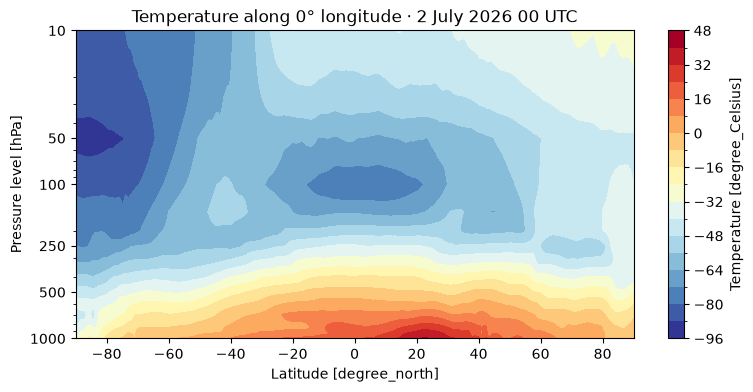

In [7]:
cross_section = single_pressure["temperature"].sel(init_time="2026-07-01T00", lead_time="24h").sel(longitude=0.0, method="nearest")
plot = cross_section.plot.contourf(
    x="latitude",
    y="pressure_level",
    yscale="log",
    yincrease=False,
    yticks=[1000, 500, 250, 100, 50, 10],
    levels=20,
    center=False,
    cmap="RdYlBu_r",
    figsize=(9, 4),
)
plot.axes.set(title="Temperature along 0° longitude · 2 July 2026 00 UTC", yticklabels=[1000, 500, 250, 100, 50, 10]);

## How do the three cloud layers differ?

Low, medium and high cloud cover describe different layers of the atmosphere. These AIFS Single maps show their forecast coverage over the North Atlantic and Europe at 00 UTC on 2 July 2026.

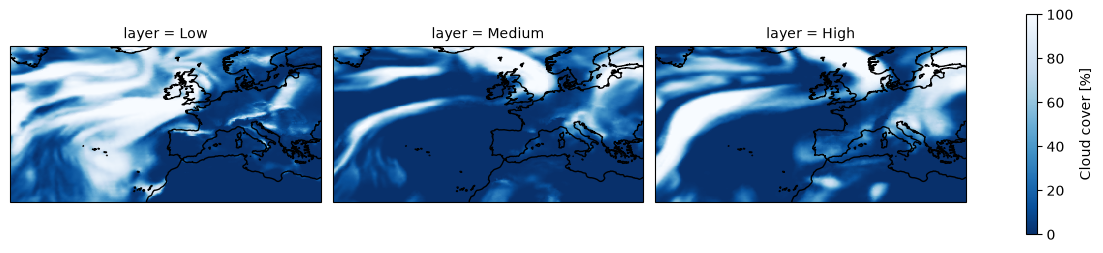

In [8]:
clouds = (
    single[["low_cloud_cover", "medium_cloud_cover", "high_cloud_cover"]]
    .sel(init_time="2026-07-01T00", lead_time="24h", latitude=slice(65, 25), longitude=slice(-50, 30))
    .to_array("layer")
    .assign_coords(layer=["Low", "Medium", "High"])
)
clouds.attrs = {"long_name": "Cloud cover", "units": "%"}
grid = clouds.plot(
    col="layer",
    transform=ccrs.PlateCarree(),
    subplot_kws={"projection": ccrs.PlateCarree()},
    cmap="Blues_r",
    vmin=0,
    vmax=100,
    size=2.5,
    aspect=1.5,
)
for ax in grid.axs.flat:
    ax.coastlines()

## How fast do the ensemble members diverge?

[France experienced a heatwave from 8 to 18 August 2025](https://meteofrance.com/actualites/vague-de-chaleur-du-8-au-18-aout-2025-retour-sur-un-episode-exceptionnel). In the 8 August 00 UTC run, contours show ensemble-mean 500 hPa geopotential height and shading shows its standard deviation across members, every 12 hours for ten days; the height field traces the large-scale ridges and troughs.

In [9]:
height = (
    ens_pressure["geopotential_height"]
    .sel(init_time="2025-08-08T00", lead_time=pd.timedelta_range("0h", "240h", freq="12h"), pressure_level=500)
    .sel(latitude=slice(65, 30), longitude=slice(-25, 30))
    .isel(latitude=slice(None, None, 4), longitude=slice(None, None, 4))
    .load()
)
mean_height = height.mean("ensemble_member", keep_attrs=True)
spread = height.std("ensemble_member")
spread.attrs = {"long_name": "500 hPa geopotential height spread", "units": "m"}

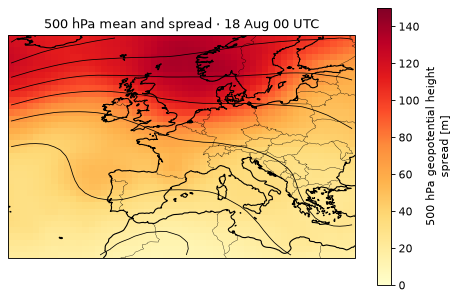

In [10]:
from IPython.display import HTML
from matplotlib.animation import FuncAnimation

fig, ax = plt.subplots(figsize=(7, 4.5), dpi=80, subplot_kw={"projection": ccrs.PlateCarree()})
spread.isel(lead_time=-1).plot(
    ax=ax,
    transform=ccrs.PlateCarree(),
    vmin=0,
    vmax=150,
    cmap="YlOrRd",
)


def update(i: int) -> None:
    ax.clear()
    spread.isel(lead_time=i).plot(
        ax=ax,
        transform=ccrs.PlateCarree(),
        vmin=0,
        vmax=150,
        cmap="YlOrRd",
        add_colorbar=False,
    )
    mean_height.isel(lead_time=i).plot.contour(
        ax=ax,
        transform=ccrs.PlateCarree(),
        levels=range(5400, 6001, 60),
        colors="black",
        linewidths=0.7,
    )
    ax.coastlines()
    ax.add_feature(cfeature.BORDERS, linewidth=0.3)
    ax.set_title(f"500 hPa mean and spread · {height.valid_time[i].dt.strftime('%d %b %H UTC').item()}")


anim = FuncAnimation(fig, update, frames=height.sizes["lead_time"], interval=250, init_func=lambda: update(-1))
HTML(anim.to_jshtml())

## Community challenge

- For the same events and initialization times, how do AIFS Single and the AIFS ENS control differ, and which differences persist across runs?
- How does AIFS ENS spread compare with [IFS ENS virtual](https://dynamical.org/catalog/ecmwf-ifs-ens-forecast-15-day-0-25-degree-virtual/) at matched lead times, and how well does each track forecast error?
- Across the [12 May 2026 06 UTC model upgrade](https://forum.ecmwf.int/t/confirmation-ifs-cycle-50r1-and-aifs-v2-joint-implementation-on-12-may-2026/14937), do changes in ensemble spread depend on the variable, region or lead time?